# Predicting Student Math Grades

Dataset: [UCI Student Performance](https://archive.ics.uci.edu/dataset/320/student+performance) (math course, 395 students).
Target: `G3` (final grade, 0-20).

**Main question:** how much of the final grade can be predicted, and how much of that comes only from the previous period grades (`G1`, `G2`)?

To answer it, every model is trained twice: once **with** `G1`/`G2` and once **without** them.

# Import Libraries

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.dummy import DummyRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import cross_validate, train_test_split
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score, root_mean_squared_error
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

# Load Dataset

In [2]:
df = pd.read_csv('./data/student-mat.csv', sep=';')
print(df.shape)
df.head()

(395, 33)


,school,sex,age,address,famsize,Pstatus,Medu,Fedu,Mjob,Fjob,...,famrel,freetime,goout,Dalc,Walc,health,absences,G1,G2,G3
0,GP,F,18,U,GT3,A,4,4,at_home,teacher,...,4,3,4,1,1,3,6,5,6,6
1,GP,F,17,U,GT3,T,1,1,at_home,other,...,5,3,3,1,1,3,4,5,5,6
2,GP,F,15,U,LE3,T,1,1,at_home,other,...,4,3,2,2,3,3,10,7,8,10
3,GP,F,15,U,GT3,T,4,2,health,services,...,3,2,2,1,1,5,2,15,14,15
4,GP,F,16,U,GT3,T,3,3,other,other,...,4,3,2,1,2,5,4,6,10,10


# Quick Look at the Target

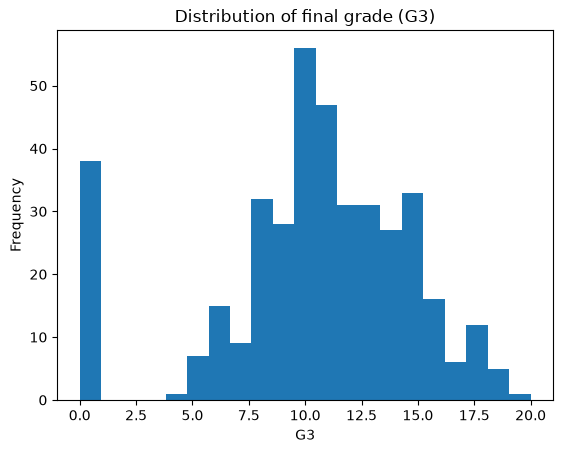

Students with G3 = 0: 38


In [3]:
df['G3'].plot(kind='hist', bins=21, title='Distribution of final grade (G3)')
plt.xlabel('G3')
plt.show()

print('Students with G3 = 0:', (df['G3'] == 0).sum())

Note the group of students with `G3 = 0` (most likely students who did not take the final exam). A plain linear model handles these points poorly, which is part of why the errors stay high.

# Data Preprocessing

In [4]:
X = df.drop(columns=['G3'])
y = df['G3']

# yes/no columns -> 1/0
yes_no_cols = ['activities', 'romantic', 'famsup', 'schoolsup', 'paid', 'higher', 'internet', 'nursery']
for col in yes_no_cols:
    X[col] = X[col].map({'yes': 1, 'no': 0})

# two-value columns -> 1/0
X['famsize'] = X['famsize'].map({'LE3': 1, 'GT3': 0})
X['Pstatus'] = X['Pstatus'].map({'T': 1, 'A': 0})

# remaining categorical columns -> one-hot
X = pd.get_dummies(X, columns=['sex', 'address', 'school', 'Mjob', 'Fjob', 'reason', 'guardian'], drop_first=True)

# two versions of the features
X_with_grades = X                                   # includes G1 and G2
X_no_grades = X.drop(columns=['G1', 'G2'])          # social / behavioral features only

print('With G1/G2   :', X_with_grades.shape)
print('Without G1/G2:', X_no_grades.shape)

With G1/G2   : (395, 41)
Without G1/G2: (395, 39)


# Models and Baseline

Three models are compared:

- **Baseline (always predict the mean):** a "dumb" model. Any real model has to beat it to be worth anything.
- **Linear Regression:** the simple model from the first version of this project.
- **Random Forest:** can capture non-linear relationships.

Scores come from 5-fold cross-validation, so the result does not depend on one lucky or unlucky train/test split (the dataset has only 395 rows).

In [5]:
models = {
    'Baseline (mean)': DummyRegressor(strategy='mean'),
    'Linear Regression': LinearRegression(),
    'Random Forest': RandomForestRegressor(n_estimators=200, random_state=42),
}

feature_sets = {
    'With G1/G2': X_with_grades,
    'Without G1/G2': X_no_grades,
}

rows = []
for set_name, features in feature_sets.items():
    for model_name, model in models.items():
        cv = cross_validate(
            model, features, y, cv=5,
            scoring=['r2', 'neg_root_mean_squared_error', 'neg_mean_absolute_error'],
        )
        rows.append({
            'Features': set_name,
            'Model': model_name,
            'R2': cv['test_r2'].mean(),
            'RMSE': -cv['test_neg_root_mean_squared_error'].mean(),
            'MAE': -cv['test_neg_mean_absolute_error'].mean(),
        })

results = pd.DataFrame(rows).round(2)
results

,Features,Model,R2,RMSE,MAE
0,With G1/G2,Baseline (mean),-0.06,4.58,3.46
1,With G1/G2,Linear Regression,0.78,2.04,1.36
2,With G1/G2,Random Forest,0.83,1.80,1.11
3,Without G1/G2,Baseline (mean),-0.06,4.58,3.46
4,Without G1/G2,Linear Regression,0.00,4.44,3.47
5,Without G1/G2,Random Forest,0.13,4.12,3.16


# Comparison Chart

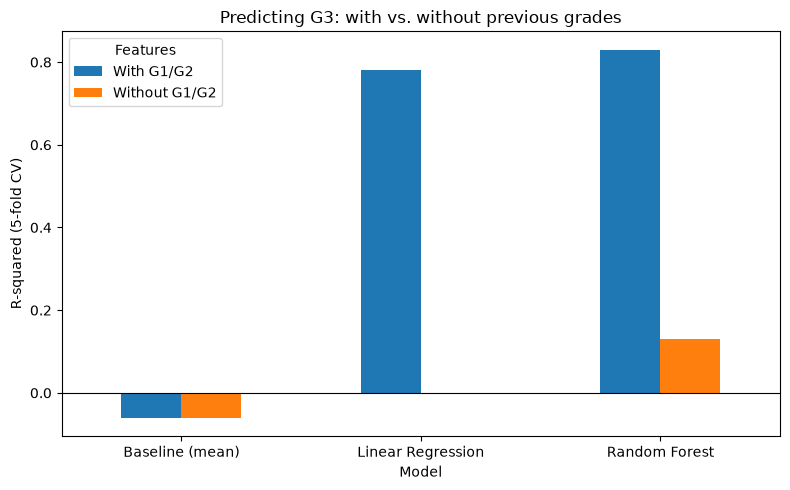

In [6]:
pivot = results.pivot(index='Model', columns='Features', values='R2')
pivot = pivot.loc[['Baseline (mean)', 'Linear Regression', 'Random Forest']]

ax = pivot.plot(kind='bar', figsize=(8, 5), rot=0)
ax.set_ylabel('R-squared (5-fold CV)')
ax.set_title('Predicting G3: with vs. without previous grades')
ax.axhline(0, color='black', linewidth=0.8)
plt.tight_layout()
plt.savefig('r2_comparison.png', dpi=150)
plt.show()

# Single Train/Test Split (Linear Regression)

The original evaluation, now run for both feature sets.

In [7]:
def holdout_report(features, label):
    X_train, X_test, y_train, y_test = train_test_split(features, y, test_size=0.2, random_state=42)
    model = LinearRegression().fit(X_train, y_train)
    y_pred = model.predict(X_test)
    print(f'--- {label} ---')
    print(f'MAE : {mean_absolute_error(y_test, y_pred):.2f}')
    print(f'MSE : {mean_squared_error(y_test, y_pred):.2f}')
    print(f'RMSE: {root_mean_squared_error(y_test, y_pred):.2f}')
    print(f'R2  : {r2_score(y_test, y_pred):.2f}')
    print()

holdout_report(X_with_grades, 'With G1/G2')
holdout_report(X_no_grades, 'Without G1/G2')

--- With G1/G2 ---
MAE : 1.65
MSE : 5.66
RMSE: 2.38
R2  : 0.72

--- Without G1/G2 ---
MAE : 3.40
MSE : 17.60
RMSE: 4.20
R2  : 0.14



# Which Features Matter? (without G1/G2)

Two views, both on the no-grades feature set:

1. Random Forest feature importance.
2. Linear Regression coefficients after standardizing the features, so they are comparable with each other.

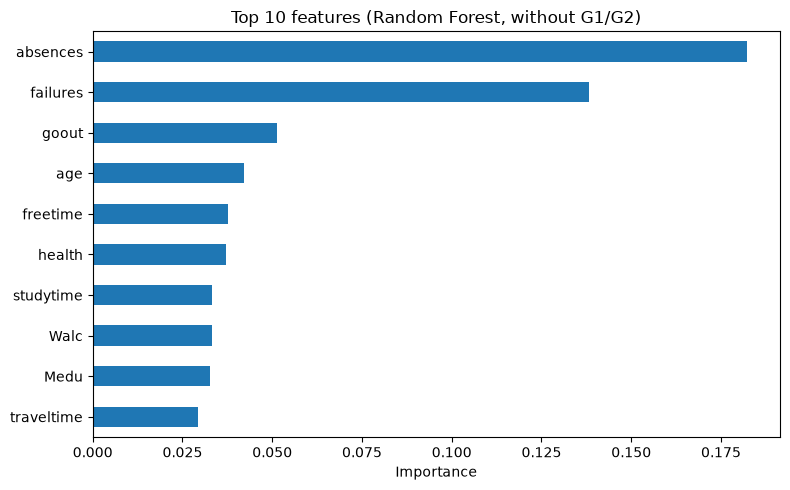

In [8]:
rf = RandomForestRegressor(n_estimators=200, random_state=42).fit(X_no_grades, y)
importances = pd.Series(rf.feature_importances_, index=X_no_grades.columns).sort_values().tail(10)

importances.plot(kind='barh', figsize=(8, 5), title='Top 10 features (Random Forest, without G1/G2)')
plt.xlabel('Importance')
plt.tight_layout()
plt.savefig('feature_importance.png', dpi=150)
plt.show()

In [9]:
lin = make_pipeline(StandardScaler(), LinearRegression()).fit(X_no_grades, y)
coefs = pd.Series(lin[-1].coef_, index=X_no_grades.columns)
top = coefs.reindex(coefs.abs().sort_values(ascending=False).index).head(10)

print('Top 10 standardized coefficients (positive = higher grade, negative = lower grade):')
print(top.round(2))

Top 10 standardized coefficients (positive = higher grade, negative = lower grade):
failures       -1.28
goout          -0.66
sex_M           0.63
romantic       -0.52
Medu            0.50
age            -0.48
studytime       0.46
schoolsup      -0.45
absences        0.45
Mjob_teacher   -0.44
dtype: float64


# Takeaways

*(Fill this in after running the notebook with the real data.)*

- How much do the baseline, linear regression and random forest differ with and without `G1`/`G2`?
- Which features show up as most important once `G1`/`G2` are removed?
- Limitations: small dataset (395 rows), many `G3 = 0` students, only one school subject.